### PnP

In [8]:
import os
import torch
import matplotlib.pyplot as plt
from einops import repeat

from PnP.linear_models import linear
from PnP.pnp_solver import IP_solver
from PnP.regularizer import NKD_regularizer, load_denoiser
from dataset_loaders import TestDataset, DataLoader
from utils import calculate_psnr, calculate_ssim, show_tensor_image, date_time_stamp
from PnP.regularizer import NKD_regularizer, NLM_regularizer, BM3D_regularizer, TV_regularizer
from models.NKD_linear_layer import NKD_latent_layers


class config:
    def __init__(self):
        pass

testset = TestDataset('./data/show', 'gray', 0, show=True)

test_loader = DataLoader(
    testset,
    batch_size=1,  # Process one full image at a time
    shuffle=False,
    pin_memory=True,
)

device='cuda:0' if torch.cuda.is_available() else 'cpu'

denoiser_nlm = NLM_regularizer(1, 3, 50/255)
denoiser_bm3d = BM3D_regularizer()
denoiser_TV = TV_regularizer(0.0001, 10, 0, 1, 'isotropic')
denoiser_nkd = NKD_regularizer('/home/aditya/NKD/output__concat_kl_v3_1111128_11_110_12_0215232138/ckpt/model_step_15000.pth', 
                               device, window_rad=3, denoiser_span=128)

def gaussian_kernel(size, sigma=1):
    """
    Generate a 2D Gaussian kernel using PyTorch.

    Args:
        size (int): The size of the kernel (must be an odd number).
        sigma (float): The standard deviation of the Gaussian distribution.

    Returns:
        torch.Tensor: A 2D Gaussian kernel tensor of shape (size, size).
    """
    # Create a grid of coordinates
    coords = torch.linspace(-(size - 1) / 2, (size - 1) / 2, size)
    xv, yv = torch.meshgrid(coords, coords, indexing="ij")
    
    # Calculate the Gaussian function
    kernel = torch.exp(-(xv ** 2 + yv ** 2) / (2 * sigma ** 2))
    
    # Normalize the kernel
    kernel = kernel / kernel.sum()
    return kernel

denoisers={
    'TV': denoiser_TV,
    'NLM': denoiser_nlm,
    'NKD': denoiser_nkd,
    'BM3D': denoiser_bm3d,
}

from PnP.pnp_solver import initialize_median_filter


Loading testing images...
Loaded 3 images from curr_test
Total loaded 3 images from: curr_test
Loaded 3 images for testing
Loaded model state from checkpoint: /home/aditya/NKD/output__concat_kl_v3_1111128_11_110_12_0215232138/ckpt/model_step_15000.pth


In [9]:
import numpy as np
from utils import pad, channel_list2img
from einops import repeat

torch.Size([1, 1, 512, 512])
tensor([[5.0124]], device='cuda:0', grad_fn=<MaxBackward0>)
0.00389286270365119 2.3008585259276515e-08 torch.Size([1, 17161, 1])


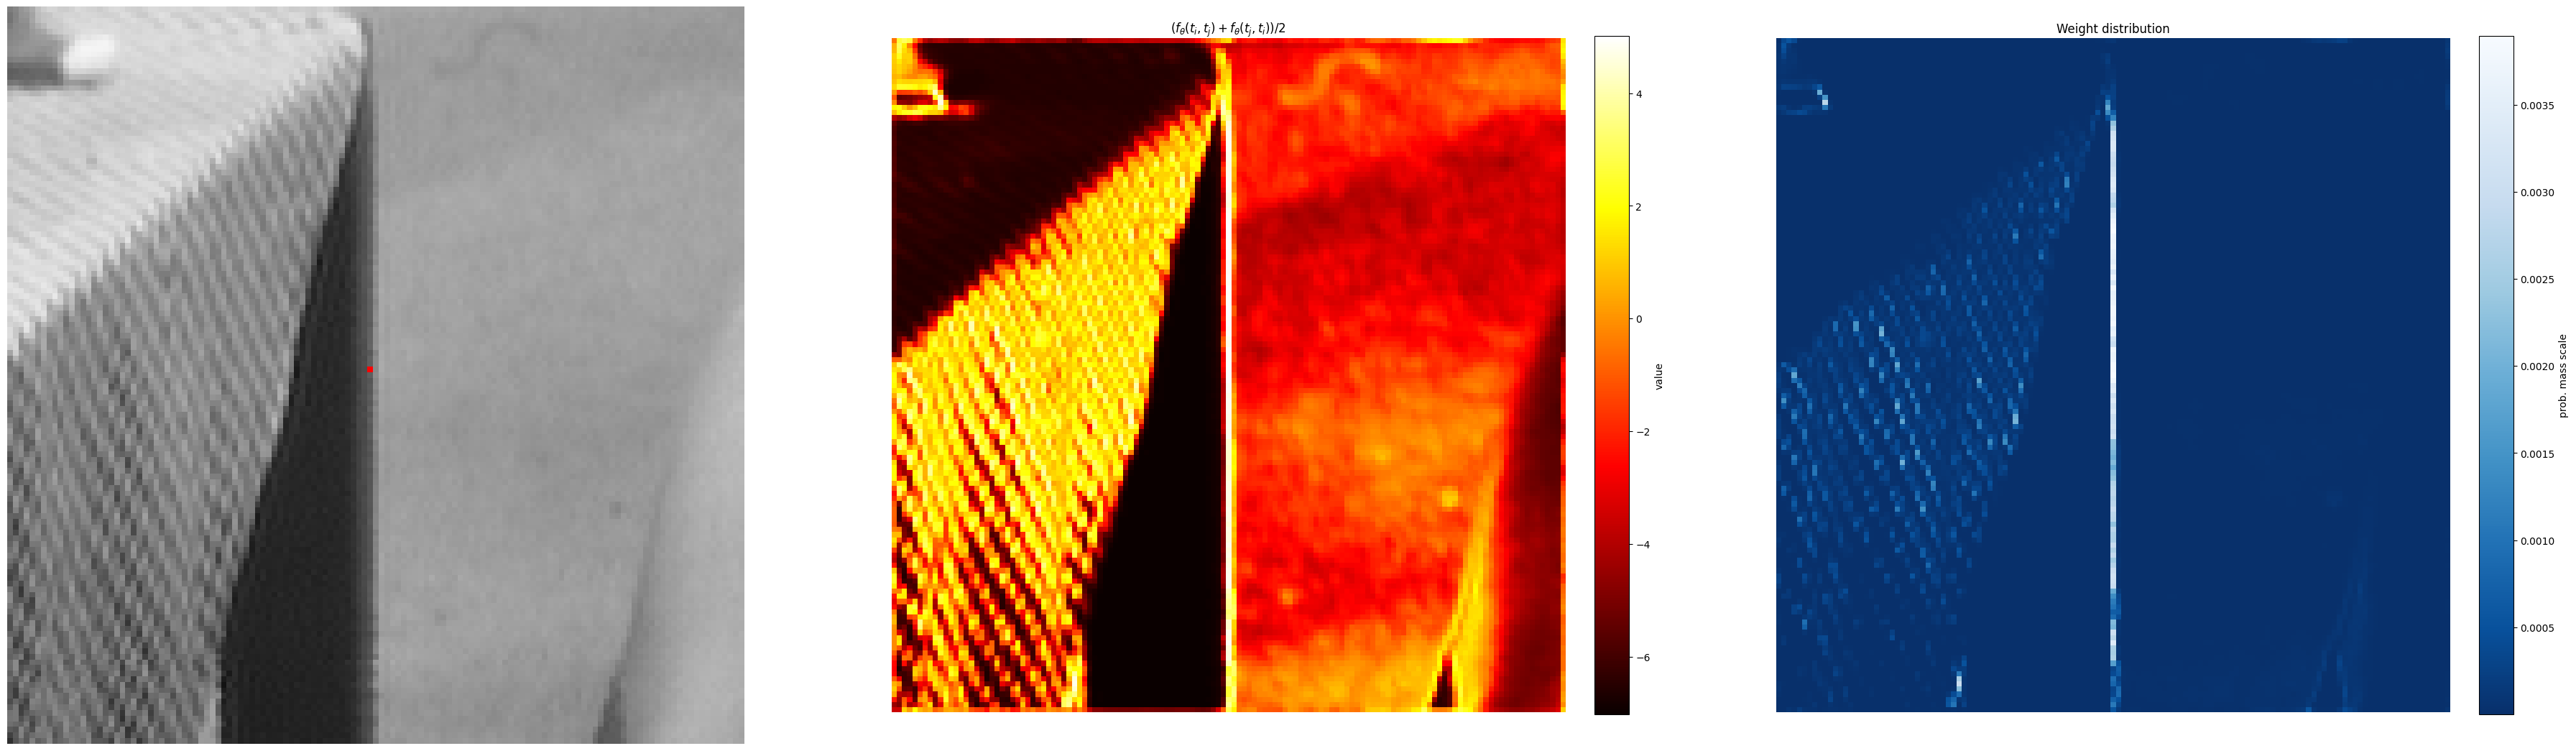

In [10]:
denoiser_nkd.denoiser.sigma = 1
# activation visualization
model = denoiser_nkd.denoiser

p = 128
for i, data in enumerate(test_loader):
    if i in [1,2]:
        continue
    # fig, axes = plt.subplots(len(name), 3, figsize=(15, 5 * len(name)))

    clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)
    b,c,m,n  = clean_image.shape

    # Move images to the same device as the model
    noisy_image = noisy_image.to(device=device, dtype=torch.float32)
    clean_image = clean_image.to(device=device, dtype=torch.float32)
    sigma = sigma.to(device=device, dtype=torch.float32)
    print(noisy_image.shape)

    i = 158
    j = 128
    # break
    pading = 2*model.patch_rad+1
    inp = noisy_image[:, :, i:i+p+pading, j:j+p+pading]
    x = pad(2*inp-1, model.patch_rad)
    x = model._pre_process_input(x)
    
    x = model._concat_patch_central_pixel(x)
    x = torch.cat(x, dim=1)

    for i in range(model.proj_depth):
        x = model.proj[i](x)
        if model.proj_res_flag:
            x = x + model.proj_residual[i](x)
            x = model.proj_norm[i](x)
        # print('xc', x)

    # print('xd', x.shape)
    x = model.out(x)
    x1,x2 = torch.chunk(x, chunks=2, dim=1)
    # print('x1', x1.shape)
    guide1 = (x1+x2)/(-2*model.sigma)
    print(torch.max(guide1, dim=1)[0])
    guide = guide1 - torch.max(guide1, dim=1)[0][:, None,:].expand_as(guide1)
    guide = torch.exp(guide)
    guide = guide/torch.sum(guide, dim=1)

    print(torch.max(guide).item(), torch.min(guide).item(), guide.shape)
    acts = channel_list2img(guide, inp.size(-2),inp.size(-1))
    break

inp1 = torch.cat((inp, inp), dim=1)
inp = torch.cat((inp1, inp), dim=1)
inp[0, 0, p//2, p//2] = 1
inp[0, 1, p//2, p//2] = 0
inp[0, 2, p//2, p//2] = 0
plt.figure(figsize=(45, 15))
plt.subplot(1,3,1)
plt.imshow(inp.permute(0, 2, 3, 1).detach().squeeze().cpu().numpy())
plt.axis('off')
plt.subplot(1,3,2)
plt.imshow(channel_list2img(guide1, inp.size(-2),inp.size(-1)).detach().squeeze().cpu().numpy(), cmap='hot')
plt.title(r'$(f_{\theta}(t_i, t_j) + f_{\theta}(t_j, t_i))/2$')
cbar = plt.colorbar(label='value', fraction=0.046, pad=0.04)
plt.axis('off')
plt.subplot(1,3,3)
plt.imshow(acts.detach().squeeze().cpu().numpy(), cmap='Blues_r')
plt.title('Weight distribution')
plt.axis('off')
cbar = plt.colorbar(label='prob. mass scale', fraction=0.046, pad=0.04)
plt.show()


In [4]:
# # activation visualization
# model = denoiser_nkd.denoiser

# p = 121
# for i, data in enumerate(test_loader):
#     if not i in [1,2]:
#         continue

#     clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)
#     b,c,m,n  = clean_image.shape

#     # Move images to the same device as the model
#     noisy_image = noisy_image.to(device=device, dtype=torch.float32)
#     clean_image = clean_image.to(device=device, dtype=torch.float32)
#     sigma = sigma.to(device=device, dtype=torch.float32)

#     i = np.random.randint(0, noisy_image.size(-2)//2, (1,))[0]
#     j = np.random.randint(0, noisy_image.size(-1)//2, (1,))[0]
#     # break
#     inp = noisy_image[:, :, i:i+p, j:j+p]
#     xp = pad(2*inp-1, model.patch_rad)

#     x = model._pre_process_input(xp)
#     print(x.shape)
    
#     ip, jp = 65, 50
#     central_pixel = x[:,ip*xp.size(1)+jp,:][:,None,:].expand_as(x)
#     x = (torch.cat((x,central_pixel), dim=-1), 
#         torch.cat((central_pixel,x), dim=-1))
#     x = torch.cat(x, dim=1)

#     for i in range(model.proj_depth):
#         x = model.proj[i](x)
#         if model.proj_res_flag:
#             x = x + model.proj_residual[i](x)
#             x = model.proj_norm[i](x)
#     x = model.out(x)
#     x1,x2 = torch.chunk(x, chunks=2, dim=1)
#     guide = (x1+x2)/(-2*model.sigma)
#     guide = torch.exp(guide)

#     print(torch.max(guide).item(), torch.min(guide).item())
#     acts = channel_list2img(guide, inp.size(-2),inp.size(-1))
#     print("activations",acts.shape)
#     break
# inp1 = torch.cat((inp, inp), dim=1)
# inp = torch.cat((inp1, inp), dim=1)
# inp[0, 0, ip, jp] = 1
# inp[0, 1, ip, jp] = 0
# inp[0, 2, ip, jp] = 0
# print(inp[0, :, ip, jp])
# plt.figure(figsize=(15,15))
# plt.imshow(inp.permute(0,2,3,1).detach().squeeze().cpu().numpy())
# plt.show()
# plt.figure(figsize=(15,15))
# plt.imshow(acts.detach().squeeze().cpu().numpy())
# plt.show()


In [5]:
# # plots
# model = denoiser_nkd.denoiser
# patch_size = model.patch_rad * 2 + 1
# in_channel = model.in_channel
# in_dim=model.in_channel*patch_size*patch_size

# inp1 = torch.ones(1, in_dim).to(device)
# inp2 = torch.zeros(1, in_dim).to(device)
# # inp1[0,0] = 1
# inp2[0,-1] = 1

# # inp1 = torch.rand(1, in_dim).to(device)
# # inp2 = torch.rand(1, in_dim).to(device)


# T = torch.linspace(0, 1, 1000)
# # print(T)
# model.eval()

# step = 1
# for a in np.arange(0, step+1)/step:
#     print('alpha = ', a)
#     inp = a*inp1 + (1-a)*inp2
#     ker = []
#     for t in T:
#         with torch.no_grad():
#             x = model._get_pre_activation(2*(t*inp)-1)
#             x = torch.cat((x, x), dim=1)

#             for i in range(model.proj_depth):
#                 x = model.proj[i](x)
#                 if model.proj_res_flag:
#                     x = x + model.proj_residual[i](x)
#                     x = model.proj_norm[i](x)
#                 # print('xc', x)

#             # print('xd', x.shape)
#             out = model.out(x)/(-model.sigma)
#             # print('xe', x)
#             # out = torch.exp(out)
#         ker.append((out.item()))
#     plt.plot(T, ker)
#     plt.title('kronecker(pre-exponent)'if a==0 else 'ones(pre-exponent)')
#     plt.show()
#     plt.close()

Tune NLM and TV

In [6]:
# params = config()
# params.device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
# for patch_rad in [1, 3]:
#     for window_rad in [3, 5, 7]:
#         for sigma in range(10, 40):
#             denoiser = NLM_regularizer(patch_rad, window_rad, sigma/255)
#             name = ['NLM']

#             print(f"patch: {patch_rad}, window: {window_rad}, sigma: {sigma}")
#             for i, data in enumerate(test_loader):
#                 # fig, axes = plt.subplots(len(name), 3, figsize=(15, 5 * len(name)))

#                 clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)
#                 b,c,m,n  = clean_image.shape
#                 i_str, j_str = 0, n-375
#                 i_stp, j_stp = 250, n-50
#                 # Move images to the same device as the model
#                 noisy_image = noisy_image.to(device=device, dtype=torch.float32)
#                 clean_image = clean_image.to(device=device, dtype=torch.float32)
#                 sigma = sigma.to(device=device, dtype=torch.float32)
                
#                 ## solver parameters
#                 # Declare linear restoration model
#                 _, _, h, w = noisy_image.shape
#                 # #inpainting
#                 # mask = (torch.rand(1, 1, h, w) <= 0.3).to(device)

#                 # params.x0 = initialize_median_filter(params.b, params.mask)
#                 #gaussian blur
#                 kernel = gaussian_kernel(11,  1.6).to(device)
#                 params.linear_op = linear('blur', kernel)

#                 distorted_image = params.linear_op.A(noisy_image)
#                 params.x0 = distorted_image

#                 # Algorithm parameters
#                 params.ker = kernel
#                 params.guide_iter=20
#                 params.b = distorted_image
#                 params.ground_truth = clean_image
#                 params.sigma = sigma
#                 params.L = 0.9
#                 params.tol = 1e-2
#                 params.device= device

#                 distorted_image_np = distorted_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
#                 clean_image_np = clean_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
                
#                 psnr_dist = calculate_psnr(clean_image, distorted_image)
#                 print(f'({psnr_dist:.2f}dB)')    
#                 plt.imshow(distorted_image_np)
#                 plt.axis('off')
#                 plt.tight_layout()
#                 plt.savefig(f'./out_{i}_n_.png')
                
#                 plt.imshow(clean_image_np)
#                 # plt.set_title(f'Clean Image')
#                 plt.axis('off')
#                 plt.tight_layout()
#                 plt.savefig(f'./out_{i}_c_.png')

#                 for j, denoiser in enumerate([denoiser]):
#                     print(f'image:{i+1}/{len(test_loader)}, denoiser:{j+1}/{len(name)}')

#                     if name[j]=='BM3D':
#                         params.max_iter = 50
#                     else:
#                         params.max_iter = 100
#                     # Pass the noisy image through the model to get the denoised image
                    
#                     # Declare regularizer
#                     params.regularizer = denoiser
#                     if name[j] =='BM3D':
#                         params.sigma = sigma*1.9
#                         params.sigma = sigma*1.9

#                     # create solver
#                     solver = IP_solver(params)

#                     with torch.no_grad():
#                         # restored_image, norm_xk, norm_error = solver.ISTA()
#                         restored_image, norm_xk, norm_error = solver.ISTA()

#                     # Calculate PSNR of denoised image
#                     psnr = calculate_psnr(clean_image, restored_image)
#                     # calculate PSNR of noisy image
#                     # psnr_dist = calculate_psnr(clean_image, distorted_image)

#                     # Convert tensors to numpy arrays for plotting
#                     # distorted_image_np = distorted_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
#                     # clean_image_np = clean_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
#                     restored_image_np = restored_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)

#                     # # Plot the images
#                     # axes[j,0].imshow(distorted_image_np)
#                     # axes[j,0].set_title(f'Distorted Image({psnr_dist:.2f}dB)')
#                     # axes[j,0].axis('off')

#                     plt.imshow(restored_image_np)
#                     print(f'{name[j]}: Restored Image({psnr:.2f}dB)')
#                     plt.axis('off')
#                     plt.tight_layout()
#                     plt.savefig(f'./out_{i}_r_{name[j]}.png')

#                     # axes[j,2].imshow(clean_image_np)
#                     # axes[j,2].set_title(f'Clean Image')
#                     # axes[j,2].axis('off')

#                 # plt.tight_layout()
#                 # plt.show()

In [16]:
params = config()
params.device = device
time_stamp = date_time_stamp()
grid = (len(denoisers), 3)
for i, data in enumerate(test_loader):
    # fig, axes = plt.subplots(len(name), 3, figsize=(15, 5 * len(name)))

    clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)
    b,c,m,n  = clean_image.shape

    # Move images to the same device as the model
    noisy_image = noisy_image.to(device=device, dtype=torch.float32)
    clean_image = clean_image.to(device=device, dtype=torch.float32)
    sigma = sigma.to(device=device, dtype=torch.float32)

    ## solver parameters

    # Declare linear restoration model
    #inpainting
    mask = (torch.rand(1, 1, noisy_image.size(-2), noisy_image.size(-1)) <= 0.3).to(device)
    params.linear_op = linear('inpnt', mask)
    distorted_image = params.linear_op.A(noisy_image)
    # print(distorted_image.shape)
    params.x0 = initialize_median_filter(distorted_image, mask)

    # #gaussian blur
    # kernel = gaussian_kernel(11,  1.6).to(device)
    # params.linear_op = linear('blur', kernel)
    # distorted_image = params.linear_op.A(noisy_image)
    # params.x0 = distorted_image
    # params.ker = kernel

    #distorted image

    # Algorithm parameters
    params.guide_iter=12
    params.b = distorted_image
    params.ground_truth = clean_image
    params.sigma = sigma
    params.L = 0.8
    params.tol = 1e-2
    params.device= device

    psnr_dist = calculate_psnr(clean_image, distorted_image)
    ssim_dist = calculate_ssim(clean_image, distorted_image)

    titles = []
    images = []
    psnr_values = {'noisy': psnr_dist}
    ssim_values = {'noisy': ssim_dist}

    for j, name in enumerate(denoisers):
        print(f'image:{i+1}/{len(test_loader)}, denoiser:{name}')

        if name=='BM3D':
            params.max_iter = 50
        else:
            params.max_iter = 100
        # Pass the noisy image through the model to get the denoised image
        
        # Declare regularizer
        params.regularizer = denoisers[name]
        if name =='BM3D':
            params.sigma = sigma*1.9
            params.sigma = sigma*1.9

        # create solver
        solver = IP_solver(params)

        with torch.no_grad():
            restored_image, norm_xk, norm_error = solver.ISTA()

        # Calculate PSNR of denoised image
        psnr = calculate_psnr(clean_image, restored_image)
        ssim = calculate_ssim(clean_image, restored_image)
        
        psnr_values[name.replace(' \n', '')] = psnr
        ssim_values[name.replace(' \n', '')] = ssim

        images.append(distorted_image)
        titles.append(f'Distorted Image({psnr_dist:.2f}dB)')

        images.append(restored_image)
        titles.append(f'{name}: Denoised Image({psnr:.2f}dB)')

        images.append(clean_image)
        titles.append(f'Clean Image')

    show_tensor_image(images, grid, titles, save=True, save_path=os.path.join('./', f'saved_test_PnP_{i}_{time_stamp}.png'))
    break


image:1/3, denoiser:TV


100%|██████████| 100/100 [00:00<00:00, 165.27it/s]


image:1/3, denoiser:NLM


100%|██████████| 100/100 [00:03<00:00, 27.60it/s]


image:1/3, denoiser:NKD


100%|██████████| 100/100 [01:33<00:00,  1.07it/s]


image:1/3, denoiser:BM3D


100%|██████████| 50/50 [01:32<00:00,  1.85s/it]


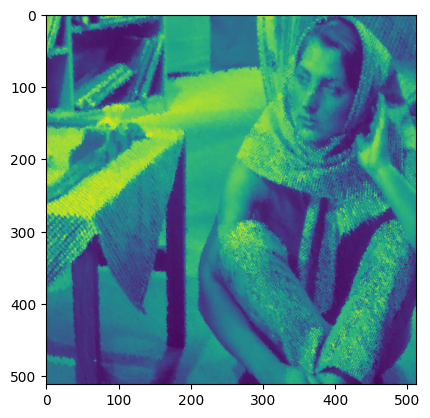

In [11]:
plt.imshow(params.x0.detach().squeeze().cpu().numpy())

**plot learing rate scheduler**

/opt/anaconda3/envs/nkd-aditya/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/nkd-aditya/lib/python3.13/site-packages/torch/optim/lr_scheduler.py:224: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


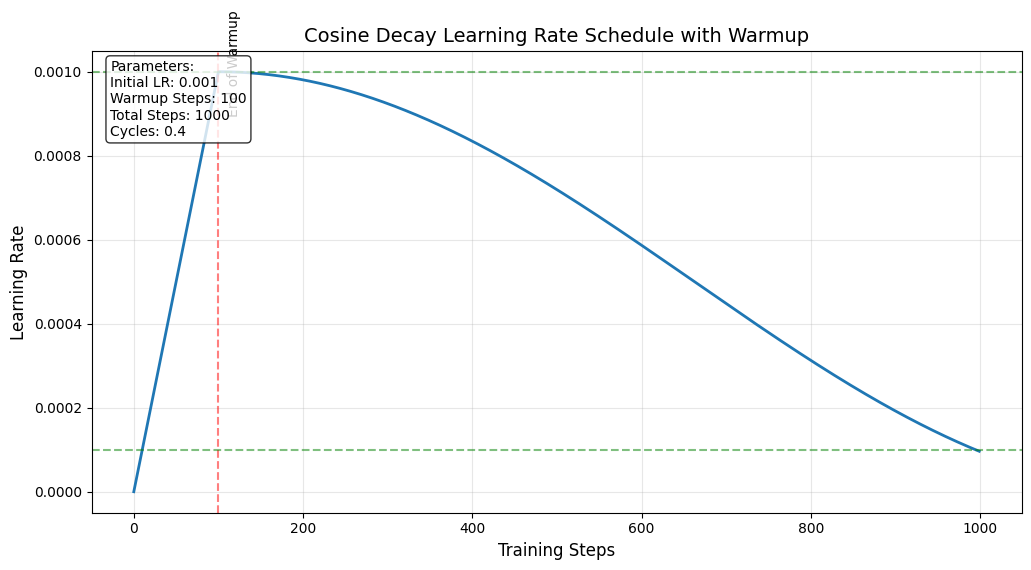

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from transformers import get_cosine_schedule_with_warmup
import torch

def plot_cosine_decay_schedule(
    num_training_steps=1000,
    num_warmup_steps=100,
    num_cycles=0.4,
    min_lr_factor=0.1,
    initial_lr=0.001
):
    """
    Plot the cosine decay learning rate schedule with warmup.
    
    Args:
        num_training_steps (int): Total number of training steps
        num_warmup_steps (int): Number of warmup steps
        num_cycles (float): Number of cycles in the cosine decay
        min_lr_factor (float): Minimum learning rate factor
        initial_lr (float): Initial learning rate
    """
    # Create a dummy optimizer
    dummy_model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.AdamW(dummy_model.parameters(), lr=initial_lr)
    
    # Create the scheduler
    scheduler = get_cosine_schedule_with_warmup(
        optimizer=optimizer,
        num_warmup_steps=num_warmup_steps,
        num_training_steps=num_training_steps,
        num_cycles=num_cycles
    )
    
    # Collect learning rates
    lrs = []
    for _ in range(num_training_steps-100):
        lrs.append(scheduler.get_last_lr()[0])
        scheduler.step()
    state = scheduler.state_dict()
    scheduler = None
    
    scheduler = get_cosine_schedule_with_warmup(
        optimizer=optimizer,
        num_warmup_steps=num_warmup_steps,
        num_training_steps=num_training_steps,
        num_cycles=num_cycles
    )
    scheduler.load_state_dict(state)
    
    for _ in range(100):
        lrs.append(scheduler.get_last_lr()[0])
        scheduler.step()
    
    # Create the plot
    plt.figure(figsize=(12, 6))
    plt.plot(lrs, linewidth=2)
    
    # Add vertical line for warmup end
    plt.axvline(x=num_warmup_steps, color='r', linestyle='--', alpha=0.5)
    plt.text(num_warmup_steps + 10, max(lrs) * 0.9, 'End of Warmup', rotation=90)
    
    # Add horizontal lines for initial and minimum LR
    plt.axhline(y=initial_lr, color='g', linestyle='--', alpha=0.5)
    plt.axhline(y=initial_lr * min_lr_factor, color='g', linestyle='--', alpha=0.5)
    
    # Customize the plot
    plt.title('Cosine Decay Learning Rate Schedule with Warmup', fontsize=14)
    plt.xlabel('Training Steps', fontsize=12)
    plt.ylabel('Learning Rate', fontsize=12)
    plt.grid(True, alpha=0.3)
    
    # Add text box with parameters
    params_text = f'Parameters:\n' \
                 f'Initial LR: {initial_lr}\n' \
                 f'Warmup Steps: {num_warmup_steps}\n' \
                 f'Total Steps: {num_training_steps}\n' \
                 f'Cycles: {num_cycles}'
    plt.text(0.02, 0.98, params_text, transform=plt.gca().transAxes,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    return plt

if __name__ == "__main__":
    # Plot single schedule with default parameters
    plot_cosine_decay_schedule()
    # plt.savefig('cosine_decay_single.png')
    plt.show()
    
    # # Plot multiple configurations
    # plot_multiple_schedules()
    # plt.savefig('cosine_decay_multiple.png')
    # plt.close()

### Tuning 

**NLM parameter tuning**

In [4]:
# parameter search
from models.NKD_linear_layer import calculate_psnr
from denoisers.NLM_torch import NLM_tensor


def parameter_search_NLM(test_loader, possible_patch, possible_window, possible_sigma):
    psnr = [[], []]
    # maxi = float('-inf')
    maxi = 2
    for i, (clean, noisy, sigma) in enumerate(test_loader):
        for pat in possible_patch:
            for win in possible_window:
                for sig in possible_sigma:
                    if pat > win:
                        continue


                    dn = {}
                    dn["patch_rad"] = pat
                    dn["window_rad"] = win
                    dn["sigma"] = sig/255.0

                    noisy = noisy.to(device)
                    clean = clean.to(device)
                    dn["guide_image"] = noisy.clone()
                    dn["input_image"] = noisy.clone()
                    denoised = NLM_tensor(**dn)
                    psnr[i].append(calculate_psnr(clean, denoised))
                    print(f"patch: {pat}, window: {win}, sigma: {sig}, psnr={psnr[i][-1]}")
                    # if True:
                    if psnr[i][-1]>maxi:
                        print(f"Maxi PSNR for image {i+1}: {psnr[i][-1]}")
                        maxi=psnr[i][-1]
        break
    return psnr
  
possible_patch = [1, 3]
possible_window = [6, 7, 9]
possible_sigma = list(range(50, 150, 1))

padding_dim = 0
testset = Train_img_Dataset('./data/img_train', 'gray', 30, 30, 
                        patch_size=None, imgs_per_epoch=1, req_patches=False)

test_loader = DataLoader(
    testset,
    batch_size=1,  # Process one full image at a time
    shuffle=False,
    pin_memory=True
)
   
_ = parameter_search_NLM(test_loader, possible_patch, possible_window, possible_sigma)


Loading training images...
Loaded 1 images from img_barbara
Total loaded 1 images from: img_barbara
Loaded 1 images for training
patch: 1, window: 6, sigma: 50, psnr=19.66929000745685
Maxi PSNR for image 1: 19.66929000745685
patch: 1, window: 6, sigma: 51, psnr=19.77974424567153
Maxi PSNR for image 1: 19.77974424567153
patch: 1, window: 6, sigma: 52, psnr=19.895667839052244
Maxi PSNR for image 1: 19.895667839052244
patch: 1, window: 6, sigma: 53, psnr=20.01683401895604
Maxi PSNR for image 1: 20.01683401895604
patch: 1, window: 6, sigma: 54, psnr=20.142991341691044
Maxi PSNR for image 1: 20.142991341691044
patch: 1, window: 6, sigma: 55, psnr=20.27386467177191
Maxi PSNR for image 1: 20.27386467177191
patch: 1, window: 6, sigma: 56, psnr=20.40916187957681
Maxi PSNR for image 1: 20.40916187957681
patch: 1, window: 6, sigma: 57, psnr=20.548571857463983
Maxi PSNR for image 1: 20.548571857463983
patch: 1, window: 6, sigma: 58, psnr=20.691771836495178
Maxi PSNR for image 1: 20.69177183649517

**TV parameter tuning**

In [11]:
from denoisers.TV import TV


def parameter_search_TV(test_loader, possible_lamda, tv_types=['l1-term', 'isotropic']):
    psnr = [[], []]
    # maxi = float('-inf')
    maxi = 2
    for i, (clean, noisy, sigma) in enumerate(test_loader):
        for lamda in possible_lamda:
            for tv_type in tv_types:
                noisy = noisy.to(device)
                clean = clean.to(device)
                denoiser = TV(lamda, 20, 0, 1, tv_type)
                denoised = denoiser(noisy, sigma=sigma)
                psnr[i].append(calculate_psnr(clean, denoised))
                print(f"lamda: {lamda}, tv_type: {tv_type}, psnr={psnr[i][-1]}")

                if psnr[i][-1]>maxi:
                    print(f"Maxi PSNR for image {i+1}: {psnr[i][-1]}")
                    maxi=psnr[i][-1]
        break
    return psnr

possible_lamda = np.linspace(0.04, 0.1, 1000)

_ = parameter_search_TV(test_loader, possible_lamda)


lamda: 0.04, tv_type: l1-term, psnr=24.35712682889301
Maxi PSNR for image 1: 24.35712682889301
lamda: 0.04, tv_type: isotropic, psnr=23.492370095157803
lamda: 0.04006006006006006, tv_type: l1-term, psnr=24.362837266930267
Maxi PSNR for image 1: 24.362837266930267
lamda: 0.04006006006006006, tv_type: isotropic, psnr=23.49852968137304
lamda: 0.040120120120120124, tv_type: l1-term, psnr=24.368535249759006
Maxi PSNR for image 1: 24.368535249759006
lamda: 0.040120120120120124, tv_type: isotropic, psnr=23.50468301416509
lamda: 0.04018018018018018, tv_type: l1-term, psnr=24.374217904165132
Maxi PSNR for image 1: 24.374217904165132
lamda: 0.04018018018018018, tv_type: isotropic, psnr=23.51082911295922
lamda: 0.04024024024024024, tv_type: l1-term, psnr=24.37988707206628
Maxi PSNR for image 1: 24.37988707206628
lamda: 0.04024024024024024, tv_type: isotropic, psnr=23.516968447848527
lamda: 0.0403003003003003, tv_type: l1-term, psnr=24.385542365698335
Maxi PSNR for image 1: 24.385542365698335
lamd

**sigma = 15** => **p-1, w-7, sig-62/255**

**sigma = 10** => **p-1, w-5, sig-50/255**

In [ ]:
# from dataset_loaders import TestDataset
# from dataset_loaders import Train_img_Dataset
# from torch.utils.data import Dataset, DataLoader
# import torch
# import numpy as np
# import deepinv as dinv


# # device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"
# device = 'cpu'


/opt/anaconda3/envs/nkd-aditya/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### denoising 

**2**

In [3]:
from deepinv.models import DnCNN, DRUNet, BM3D
from denoisers.NLM_torch import NLM_tensor
from denoisers.TV import TV
import deepinv as dinv
import torch
from utils import *
from dataset_loaders import Train_img_Dataset, TestDataset, DataLoader
from NKD_test import TestDenoisers, create_combined_checker_matrix
from datetime import datetime
from NKD_models import *
class config:
    def __init__(self):
        pass
    

device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"

n_channels = 3  # number of color channels in the input image

denoiser_nlm = lambda x, y : NLM_tensor(x, x, 1, 9, 110/255, False)
denoiser_bm3d = BM3D()
denoiser_tv = TV(0.079579, 20, 0, 1, 'isotropic')
denoiser_dncnn = DRUNet()
val=0

n_channels = 1  # number of color channels in the input image

device = dinv.utils.get_freer_gpu() if torch.cuda.is_available() else "cpu"



denoiser_dncnn = DnCNN(
    in_channels=n_channels,
    out_channels=n_channels,
    pretrained="./model_zoo/dncnn_sigma2_lipschitz_gray.pth",  # automatically downloads the pretrained weights, set to a path to use custom weights.
    # pretrained="download_lipchitz",
    device=device,
)
denoiser_drunet = dinv.models.DRUNet(
    in_channels=n_channels,
    out_channels=n_channels,
    pretrained="./model_zoo/drunet_deepinv_gray_finetune_26k.pth",
    # pretrained="download",
    device=device,
)

Selected GPU 0 with 44509 MiB free memory 
Selected GPU 0 with 44509 MiB free memory 


/opt/anaconda3/envs/nkd-aditya/lib/python3.13/site-packages/deepinv/models/dncnn.py:90: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(pretrained, map_locat

In [4]:
def CheckerTestDenoisers(sigma, size, denoisers, device, out_folder, p=0, state='', verbose=True):
    if verbose:
        print('==== Test ====')
    # Create a figure to save the images
    grid = (len(denoisers), 3)

    # clean_image = create_combined_checker_matrix(size=size, checker_sizes=[2**i for i in range(4)])
    clean_image = create_combined_checker_matrix(size=size)
    noisy_image = clean_image + float(sigma)/255*torch.randn_like(clean_image)

    # Move images to the same device as the model
    clean_image = unpad(clean_image.to(device=device, dtype=torch.float32), p, p)
    noisy_image = noisy_image.to(device=device, dtype=torch.float32)
    sigma = sigma * torch.ones(1, 1, 1, device=device, dtype=torch.float32)
    unpadded_noisy_image = unpad(noisy_image, p,p)
    if verbose:
        print(f'image size = {unpadded_noisy_image.shape}')

    psnr_noisy = calculate_psnr(clean_image, unpadded_noisy_image)
    ssim_noisy = calculate_ssim(clean_image, unpadded_noisy_image)

    if verbose:
        print(f'Noisy: psnr = {psnr_noisy:.2f} | ssim = {ssim_noisy:.4f}')
    titles = []
    images = []
    psnr_values = {'noisy': psnr_noisy}
    ssim_values = {'noisy': ssim_noisy}


    for j, name in enumerate(denoisers.keys()):
        # Pass the noisy image through the model to get the denoised image
        if name == 'BM3D':
            with torch.no_grad():
                denoised_image = denoisers[name](unpadded_noisy_image, sigma.squeeze().item())
            unpadded_noisy_image = unpadded_noisy_image.to(device)
            denoised_image = denoised_image.to(device)

        elif 'nkd' in name.lower():
            with torch.no_grad():
                denoisers[name].eval()
                denoised_image = denoisers[name].forward_img(noisy_image, sigma)
                if verbose:
                    print(denoised_image.shape, clean_image.shape)
        else:
            with torch.no_grad():
                denoised_image = denoisers[name](unpadded_noisy_image, sigma)
        
        # Calculate PSNR of denoised image
        if denoised_image.shape != clean_image.shape:
            h, w = denoised_image.shape[-2:]
            hc, wc = clean_image.shape[-2:]
            denoised_image = unpad(denoised_image, abs(h-hc)//2, abs(w-wc)//2)
        psnr = calculate_psnr(clean_image, denoised_image)
        ssim = calculate_ssim(clean_image, denoised_image)

        psnr_values[name.replace(' \n', '')] = psnr
        ssim_values[name.replace(' \n', '')] = ssim

        if verbose:
            print(f'{name}: psnr = {psnr:.2f} | ssim = {ssim:.4f}')
        
        images.append(unpadded_noisy_image)
        titles.append(f'Noisy Image({psnr_noisy:.2f}dB)')

        images.append(denoised_image)
        titles.append(f'{name}: Denoised Image({psnr:.2f}dB)')

        images.append(clean_image)
        titles.append(f'Clean Image')

    show_tensor_image(images, grid, titles, save=True, save_path=os.path.join(out_folder, f'saved_test_checker_{state}.png'))

    return (psnr_values, ssim_values)


In [ ]:
ckpt_list = list(range(1000, 11000, 1000))
print('checkpoints being computed:',ckpt_list)

for step in ckpt_list:
    out_folder_imgs = './checkpoint_test/output_images'
    # if not os.path.exists():
    #     os.mkdir(out_folder_imgs)
    denoiser_nkd_concat1 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_22_130_30_0210061008/ckpt/model_step_{step}.pth',
                                    device=device)[0]

    denoiser_nkd_concat2 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_23_130_30_0210160327/ckpt/model_step_{step}.pth',
                                    device=device)[0]

    denoiser_nkd_concat3 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_24_130_30_0209194911/ckpt/model_step_{step}.pth',
                                    device=device)[0]

    denoiser_nkd_concat4 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_25_130_30_0209001822/ckpt/model_step_{step}.pth',
                                    device=device)[0]

    denoiser_nkd_concat5 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_26_130_30_0211020516/ckpt/model_step_{step}.pth',
                                    device=device)[0]
    denoiser_nkd_concat1.window_rad = 10
    denoiser_nkd_concat1.sigma = 1
    denoiser_nkd_concat2.window_rad = 10
    denoiser_nkd_concat2.sigma = 1
    denoiser_nkd_concat3.window_rad = 10
    denoiser_nkd_concat3.sigma = 1
    denoiser_nkd_concat4.window_rad = 10
    denoiser_nkd_concat4.sigma = 1
    denoiser_nkd_concat5.window_rad = 10
    denoiser_nkd_concat5.sigma = 1
    denoisers = {}
    denoisers['TV'] = denoiser_tv
    denoisers['BM3D'] = denoiser_bm3d
    denoisers['NLM'] = denoiser_nlm
    denoisers['NKD kernel function learn: \n concatenate patchs w/h res. depth = 2, proj. depth 2, latent dim = 1024 \n'] = denoiser_nkd_concat1
    # denoisers['NKD kernel function learn: \n concatenate patchs w/h res. depth = 2, proj. depth 3, latent dim = 1024 \n'] = denoiser_nkd_concat2
    denoisers['NKD kernel function learn: \n concatenate patchs w/h res. depth = 2, proj. depth 4, latent dim = 1024 \n'] = denoiser_nkd_concat3
    # denoisers['NKD kernel function learn: \n concatenate patchs w/h res. depth = 2, proj. depth 5, latent dim = 1024 \n'] = denoiser_nkd_concat4
    denoisers['NKD kernel function learn: \n concatenate patchs w/h res. depth = 2, proj. depth 6, latent dim = 1024 \n'] = denoiser_nkd_concat5
    
    padding_dim = denoiser_nkd_concat5.patch_rad + denoiser_nkd_concat5.window_rad
    testset = TestDataset('./data/test_set', 'gray', 30)

    test_loader = DataLoader(
        testset,
        batch_size=1,  # Process one full image at a time
        shuffle=False,
        pin_memory=True
    )
    psnr_dicts, ssim_dicts = TestDenoisers(test_loader, denoisers, device, out_folder=out_folder_imgs, state=step, p = padding_dim, verbose=True)
    
    psnr_values, ssim_values = CheckerTestDenoisers(30, 64, denoisers, device, state=step, out_folder=out_folder_imgs, p=padding_dim, verbose=True)

    stats = {
        'psnr_dicts,TestDenoisers': psnr_dicts,
        'ssim_dicts,TestDenoisers': ssim_dicts,
        'psnr_values,CheckerTestDenoisers': psnr_values,
        'ssim_values,CheckerTestDenoisers': ssim_values
    }

    save_pickle(stats, os.path.join('./checkpoint_test/stats', f'pickle_ckpt_{step}.pkl'))
    print('Completed step:', step)

checkpoints being computed: [1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000]
Loaded model state from checkpoint: /home/aditya/NKD/output__concat_kl_5711024_22_130_30_0210061008/ckpt/model_step_1000.pth
Loaded model state from checkpoint: /home/aditya/NKD/output__concat_kl_5711024_23_130_30_0210160327/ckpt/model_step_1000.pth
Loaded model state from checkpoint: /home/aditya/NKD/output__concat_kl_5711024_24_130_30_0209194911/ckpt/model_step_1000.pth
Loaded model state from checkpoint: /home/aditya/NKD/output__concat_kl_5711024_25_130_30_0209001822/ckpt/model_step_1000.pth
Loaded model state from checkpoint: /home/aditya/NKD/output__concat_kl_5711024_26_130_30_0211020516/ckpt/model_step_1000.pth

Loading testing images...
Loaded 5 images from original
Loaded 5 images from LRbicx2
Loaded 5 images from LRbicx3
Loaded 8 images from Set12
Loaded 5 images from LRbicx4
Total loaded 28 images from: original, LRbicx2, LRbicx3, Set12, LRbicx4
Loaded 28 images for testing
==== Test ===

In [3]:
# from models.NKD_linear_layer import load_checkpoint, NKD_latent_layers_v2, NKD_latent_layers
# from NKD_models import *
# class config:
#     def __init__(self):
#         pass

# # denoiser_nkd_concat1 = NKD_denoisers.load_checkpoint('/home/aditya/NKD/output__concat_kl_4711024_25_130_30_0206024217/ckpt/model_step_50000.pth',
# #                                   device=device)[0]

# # denoiser_nkd_diff1 = NKD_denoisers.load_checkpoint('/home/aditya/NKD/output_diff_kl_4711024_25_130_30_0205211905/ckpt/model_step_50000.pth',
# #                                   device=device)[0]

# # denoiser_nkd_rbf1 = NKD_denoisers.load_checkpoint('/home/aditya/NKD/output_rbf_471102410_25_130_30_0206124720/ckpt/model_step_50000.pth',
# #                                   device=device)[0]
# step=19800

# denoiser_nkd_concat1 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_22_130_30_0210061008/ckpt/model_step_{step}.pth',
#                                   device=device)[0]

# denoiser_nkd_concat2 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_23_130_30_0210160327/ckpt/model_step_{step}.pth',
#                                   device=device)[0]

# denoiser_nkd_concat3 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_24_130_30_0209194911/ckpt/model_step_{step}.pth',
#                                   device=device)[0]

# denoiser_nkd_concat4 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_25_130_30_0209001822/ckpt/model_step_{step}.pth',
#                                   device=device)[0]

# denoiser_nkd_concat5 = NKD_denoisers.load_checkpoint(f'/home/aditya/NKD/output__concat_kl_5711024_26_130_30_0211020516/ckpt/model_step_{step}.pth',
#                                   device=device)[0]


In [4]:
# denoiser_nkd_concat1.window_rad = 10
# denoiser_nkd_concat1.sigma = 1
# # denoiser_nkd_diff1.window_rad = 10
# # denoiser_nkd_diff1.sigma = 1
# # denoiser_nkd_rbf1.window_rad = 10
# # denoiser_nkd_rbf1.sigma = 1
# denoiser_nkd_concat3.window_rad = 10
# denoiser_nkd_concat3.sigma = 1
# denoiser_nkd_concat4.window_rad = 10
# denoiser_nkd_concat4.sigma = 1
# denoiser_nkd_concat5.window_rad = 10
# denoiser_nkd_concat5.sigma = 1
# # from NKD_test import Test_denoisers
# denoisers = {}
# # denoisers['TV'] = denoiser_tv
# # denoisers['BM3D'] = denoiser_bm3d
# # denoisers['NLM'] = denoiser_nlm
# # denoisers['NKD kernel function learn: \n diff. sq. of patch features w/h patch size 9\n'] = denoiser_nkd_diff1
# # denoisers['NKD rbf feature learn: \n diff. sq. of patch features w/h patch size 9\n'] = denoiser_nkd_rbf1
# denoisers['NKD kernel function learn: \n concatenate patchs w/h proj. depth 2 \n'] = denoiser_nkd_concat1
# denoisers['NKD kernel function learn: \n concatenate patchs w/h proj. depth 3 \n'] = denoiser_nkd_concat2
# denoisers['NKD kernel function learn: \n concatenate patchs w/h proj. depth 4 \n'] = denoiser_nkd_concat3
# denoisers['NKD kernel function learn: \n concatenate patchs w/h proj. depth 5 \n'] = denoiser_nkd_concat4
# denoisers['NKD kernel function learn: \n concatenate patchs w/h proj. depth 6 \n'] = denoiser_nkd_concat5
# # denoisers['NKD kernel function learn: \n diff. sq. of patch features\n'] = denoiser_nkd_diff
# # denoisers['NKD RBG feature learning\n'] = denoiser_nkd_rbf

# padding_dim = denoiser_nkd_concat4.patch_rad + denoiser_nkd_concat4.window_rad
# testset = TestDataset('./data/test_set', 'gray', 30)

# test_loader = DataLoader(
#     testset,
#     batch_size=1,  # Process one full image at a time
#     shuffle=False,
#     pin_memory=True
# )
# # time_stamp = datetime.now().strftime("%m%d%H%M%S")
# # TestDenoisers(test_loader, denoisers, device, './', p=padding_dim, state=str(val)+str(time_stamp), verbose=True)
# # _ = CheckerTestDenoisers(30,128,denoisers,device, p=padding_dim, out_folder='./', state=str(val)+str(time_stamp), verbose=True)
# with open(os.path.join(args.out_folder, 'training_log.txt'), 'a') as f:
#     f.write(f'{epoch+1},{loss:.6f},{current_lr}\n')

In [ ]:
import pickle


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.patches import Rectangle
# import urllib.request
# from PIL import Image
# import io

# def display_image_with_crop(image_path, crop_coords, crop_size):
#     """
#     Display an image with a cropped section shown in the corner
    
#     Parameters:
#     image_path: str or URL of the image
#     crop_coords: tuple (x, y) of crop center point
#     crop_size: tuple (width, height) of crop rectangle
#     """
#     # Load the image (works with both local files and URLs)
#     try:
#         if image_path.startswith('http'):
#             response = urllib.request.urlopen(image_path)
#             image = Image.open(io.BytesIO(response.read()))
#         else:
#             image = Image.open(image_path)
#         img_array = np.array(image)
#     except Exception as e:
#         print(f"Error loading image: {e}")
#         return

#     # Calculate crop boundaries
#     x, y = crop_coords
#     w, h = crop_size
#     x1 = max(0, x - w//2)
#     x2 = min(img_array.shape[1], x + w//2)
#     y1 = max(0, y - h//2)
#     y2 = min(img_array.shape[0], y + h//2)

#     # Extract cropped region
#     cropped = img_array[y1:y2, x1:x2]

#     # Create the figure and main subplot
#     fig, ax = plt.subplots(figsize=(10, 8))
    
#     # Display main image
#     ax.imshow(img_array)
    
#     # Add rectangle to show crop area
#     rect = Rectangle((x1, y1), x2-x1, y2-y1,
#                     fill=False, color='red', linewidth=2)
#     ax.add_patch(rect)

#     # Calculate position for inset axes (top-right corner)
#     # Make it 25% of the main figure size
#     inset_width = 0.25
#     inset_height = 0.25
#     inset_x = 0.73  # Position from left
#     inset_y = 0.70  # Position from bottom

#     # Create inset axes and display cropped region
#     ax_inset = fig.add_axes([inset_x, inset_y, inset_width, inset_height])
#     ax_inset.imshow(cropped)
#     ax_inset.axis('off')
    
#     # Add a border around the inset
#     for spine in ax_inset.spines.values():
#         spine.set_color('red')
#         spine.set_linewidth(2)

#     # Remove axis from main plot
#     ax.axis('off')
    
#     plt.show()

# crop_center = (300, 200)  # (x, y) coordinates
# crop_dimensions = (100, 100)  # (width, height)
# display_image_with_crop(image_url, crop_center, crop_dimensions)

In [ ]:
if :
    print(0)

In [10]:
# import torch

# def TV_proj_p(p_q, proj_p):
#     p = p_q[0]
#     q = p_q[1]

#     if proj_p == "isotropic":
#         c, m, n = q.shape
#         mag_grad = torch.sqrt(p[:, :m-1, :n-1]**2 + q[:, :m-1, :n-1]**2)
#         p[:, :m-1, :n-1] = p[:, :m-1, :n-1] / torch.maximum(torch.tensor(1.0, dtype=torch.float32), mag_grad)
#         p[:, :, n-1] = p[:, :, n-1] / torch.maximum(torch.tensor(1.0, dtype=torch.float32), torch.abs(p[:, :, n-1]))
#         q[:, :m-1, :n-1] = q[:, :m-1, :n-1] / torch.maximum(torch.tensor(1.0, dtype=torch.float32), mag_grad)
#         q[:, m-1, :] = q[:, m-1, :] / torch.maximum(torch.tensor(1.0, dtype=torch.float32), torch.abs(q[:, m-1, :]))

#     elif proj_p == "l1-term":
#         p = p / torch.maximum(torch.tensor(1.0, dtype=torch.float32), torch.abs(p))
#         q = q / torch.maximum(torch.tensor(1.0, dtype=torch.float32), torch.abs(q))

#     return (p, q)

# def TV_proj_c(image, l, u):
#     """
#     Project tensor values to range [l, u]
    
#     Args:
#         image: Input tensor
#         l: Lower bound
#         u: Upper bound
#     Returns:
#         Projected tensor with values clamped between l and u
#     """
#     return torch.clamp(image, min=l, max=u)

# class L_image_grad:
#     def __init__(self):
#         pass
        
#     def L_T(self, image):
#         """
#         Transpose gradient operator
#         Args:
#             image: Input tensor of shape (c, m, n)
#         Returns:
#             tuple of tensors (p, q) containing vertical and horizontal differences
#         """
#         c, m, n = image.shape
#         p = image[:, :m-1, :] - image[:, 1:m, :]
#         q = image[:, :, :n-1] - image[:, :, 1:n]
#         return (p, q)

#     def L(self, p_q):
#         """
#         Gradient operator
#         Args:
#             p_q: tuple of tensors (p, q) containing vertical and horizontal components
#         Returns:
#             tensor of shape (c, m, n)
#         """
#         p, q = p_q
#         c, m, n = q.shape[0], p.shape[1] + 1, q.shape[2] + 1
#         x = torch.zeros((c, m, n), dtype=p.dtype, device=p.device)
        
#         x[:, :m-1, :] += p
#         x[:, 1:m, :] -= p
#         x[:, :, :n-1] += q
#         x[:, :, 1:n] -= q
#         return x

# def FGP_color(x, params):
#     """
#     FGP implementation for color images with channels processed in parallel using PyTorch.

#     Args:
#         x: Input color image tensor of shape (C, M, N)
#         params: Parameters containing lamda, iters, l, u, proj_p

#     Returns:
#         Processed color image tensor of shape (C, M, N)
#     """
#     # Check if input has valid shape
#     if len(x.shape) != 3:
#         raise ValueError("Input image must have shape (C, M, N)")

#     ops = L_image_grad()
#     c, m, n = x.shape
#     device = x.device
#     x_star = torch.zeros_like(x)

#     # Initialize variables for all channels in parallel
#     pk_minus_1 = rk = torch.zeros((c, m - 1, n), dtype=torch.float32, device=device)
#     qk_minus_1 = sk = torch.zeros((c, m, n - 1), dtype=torch.float32, device=device)
#     tk = torch.ones((c,), dtype=torch.float32, device=device)

#     for i in range(params.iters):
#         # Apply FGP algorithm for all channels in parallel
#         Pc = TV_proj_c(x - params.lamda * ops.L((rk, sk)), params.l, params.u)
#         temp_p, temp_q = ops.L_T(Pc)
#         temp_p = rk + (1 / (8 * params.lamda)) * temp_p
#         temp_q = sk + (1 / (8 * params.lamda)) * temp_q
#         pk, qk = TV_proj_p((temp_p, temp_q), params.proj_p)

#         tk_plus_1 = (1 + torch.sqrt(1 + 4 * tk**2)) / 2

#         rk = pk + (tk.view(-1, 1, 1) - 1) / tk_plus_1.view(-1, 1, 1) * (pk - pk_minus_1)
#         sk = qk + (tk.view(-1, 1, 1) - 1) / tk_plus_1.view(-1, 1, 1) * (qk - qk_minus_1)

#         pk_minus_1 = pk
#         qk_minus_1 = qk
#         tk = tk_plus_1

#     # Calculate the final result for all channels in parallel
#     x_star = TV_proj_c(x - params.lamda * ops.L((pk, qk)), params.l, params.u)

#     return x_star


## 1

In [13]:
from NKD_linear_layer import NKD_latent_layers

class config:
    def __init__(self):
        pass

args = config()

args.seed = 100
args.in_folder = './data'
args.out_folder = './output'
args.color_mode = 'rgb'
args.sigma_min = 10
args.sigma_max = 10
args.patch_size = 128
args.epochs = 20000
args.batch_size = 20
args.lr = 1e-3
args.sch = 'cosine'
args.lr_step = None
args.lr_gamma = None
args.val_freq = 500
args.save_freq = 500
args.progress_freq = 100
args.blind = True
args.patch_rad = 5
args.window_rad = 10
args.in_channel = 3
args.latent_dim = 512
args.latent_channel_dim = 10
args.save_img_freq = 1


model = NKD_latent_layers(args.patch_rad, args.window_rad, args.in_channel, args.latent_dim, args.latent_channel_dim, 'cpu', blind=args.blind).to(device)

In [14]:
# from NKD_linear_layer import load_checkpoint
from deepinv.models import BM3D
import torch

model_ckpt = torch.load('./output_5103512101/model_5103512101_best.pth', weights_only=True)
model.load_state_dict(model_ckpt)
model

denoiser_nlm = lambda x, y : NLM(x, x, 1, 5, 50/255, False)
denoiser_bm3d = BM3D()

In [ ]:
import torch

import matplotlib.pyplot as plt
from NKD_linear_layer import calculate_psnr, calculate_ssim

# Set the model to evaluation mode
model.eval()

# Create a figure to save the images
fig, axes = plt.subplots(len(test_loader)*3, 3, figsize=(15, 5 * len(test_loader)*3))
name = ['NKD', 'NLM', 'BM3D']

# Loop through the validation loader
for i, data in enumerate(test_loader):
    clean_image, noisy_image, sigma = data  # dataset returns a tuple of (noisy_image, clean_image)
    
    # Move images to the same device as the model
    noisy_image = noisy_image.to(device=device, dtype=torch.float32)
    clean_image = clean_image.to(device=device, dtype=torch.float32)

    for j, denoiser in enumerate([model, denoiser_nlm, denoiser_bm3d]):
        # Pass the noisy image through the model to get the denoised image
        with torch.no_grad():
            denoised_image = denoiser(noisy_image, sigma)
        
        # Convert tensors to numpy arrays for plotting
        noisy_image_np = noisy_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
        denoised_image_np = denoised_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)
        clean_image_np = clean_image.squeeze().detach().cpu().numpy().transpose(1, 2, 0)

        # Calculate PSNR of denoised image
        psnr = calculate_psnr(clean_image, denoised_image)
        # calculate PSNR of noisy image
        psnr_noisy = calculate_psnr(clean_image, noisy_image)
        
        # Plot the images
        axes[i*3+j, 0].imshow(noisy_image_np)
        axes[i*3+j, 0].set_title(f'Noisy Image({psnr_noisy:.4f}dB)')    
        axes[i*3+j, 0].axis('off')
        
        axes[i*3+j, 1].imshow(denoised_image_np)
        axes[i*3+j, 1].set_title(f'Denoised Image({psnr:.4f}dB)')
        axes[i*3+j, 1].axis('off')
        
        axes[i*3+j, 2].imshow(clean_image_np)
        axes[i*3+j, 2].set_title(f'Clean Image:- {name[j]}')
        axes[i*3+j, 2].axis('off')

# Save the figure
plt.tight_layout()
plt.savefig('output_images.png')
plt.show()

In [6]:
import torch

def inf_median_filter_2d(image, kernel_radius=5):
    """
    Apply infinite median filter to a 2D image with specified kernel radius using PyTorch.
    
    Args:
        image (torch.Tensor): Input 2D image tensor
        kernel_radius (int): Radius of the kernel (should be positive)
    
    Returns:
        torch.Tensor: Filtered image with same shape as input
    """
    # Validate kernel radius
    assert kernel_radius > 0, 'Kernel radius should be greater than 0'
    if kernel_radius % 2 == 0:
        kernel_radius -= 1
    
    # Convert to float64 if not already
    image = image.to(torch.float64)
    
    # Pad with infinity
    padded_image = torch.nn.functional.pad(
        image, 
        (kernel_radius, kernel_radius, kernel_radius, kernel_radius),
        mode='constant',
        value=float('inf')
    )
    
    # Find infinity locations in original image
    infinity_indices = torch.where(torch.isinf(image))
    
    # Process each infinity pixel
    for row, col in zip(infinity_indices[0], infinity_indices[1]):
        # Convert to padded image coordinates
        row_padded = row + kernel_radius
        col_padded = col + kernel_radius
        
        # Extract patch
        patch = padded_image[
            row_padded - kernel_radius:row_padded + kernel_radius + 1,
            col_padded - kernel_radius:col_padded + kernel_radius + 1
        ]
        
        # Sort patch and handle special cases
        patch_flat = torch.sort(patch.flatten())[0]
        inf_indices = torch.where(torch.isinf(patch_flat))[0]
        
        # Skip if all values are infinity
        if len(inf_indices) == len(patch_flat):
            continue
            
        # Get valid (non-inf) values and compute median
        if len(inf_indices) == 0:
            valid_values = patch_flat
        else:
            valid_values = patch_flat[:inf_indices[0]]
            
        if len(valid_values) > 0:
            median = torch.median(valid_values)
            padded_image[row_padded, col_padded] = median
    
    # Extract and return the filtered region
    return padded_image[kernel_radius:-kernel_radius, kernel_radius:-kernel_radius]

def initialize_median_filter(observed_image, application_matrix, kernel_radius=1):
    """
    Initialize and apply median filter with increasing kernel size until all infinite values are removed.
    
    Args:
        observed_image (torch.Tensor): Original image tensor
        application_matrix (torch.Tensor): Binary matrix indicating valid pixels (1) and pixels to be filtered (0)
        kernel_radius (int): Initial kernel radius
    
    Returns:
        torch.Tensor: Filtered image with no infinite values
    """
    # Initialize image with infinities at masked locations
    initial_image = observed_image.clone()
    initial_image[application_matrix == 0] = float('inf')
    
    max_radius = min(initial_image.shape[0], initial_image.shape[1]) + 2
    
    # Iteratively apply filter with increasing kernel size
    while kernel_radius <= max_radius:
        initial_image = inf_median_filter_2d(initial_image, kernel_radius)
        
        if not torch.isinf(initial_image).any():
            break
            
        kernel_radius += 2
        
    return initial_image

def demo_median_filter():
    """
    Demonstrate usage of the PyTorch median filter implementation.
    """
    # Create sample image and application matrix
    image = torch.ones(10, 10)
    mask = torch.ones_like(image)
    mask[1:9, 1:9] = 0  # Create a region to be filtered
    image = image*mask
    
    # Apply filter
    print(image)
    filtered_image = initialize_median_filter(image, mask, kernel_radius=1)
    return filtered_image

# # Example usage with device handling
# def apply_median_filter(image, mask, kernel_radius=1, device='cpu'):
#     """
#     Apply median filter with device handling.
    
#     Args:
#         image (torch.Tensor): Input image
#         mask (torch.Tensor): Binary mask
#         kernel_radius (int): Initial kernel radius
#         device (str): Device to run the computation on
        
#     Returns:
#         torch.Tensor: Filtered image
#     """
#     # Move tensors to specified device
#     image = image.to(device)
#     mask = mask.to(device)
    
#     # Apply filter
#     filtered_image = initialize_median_filter(image, mask, kernel_radius)
    
#     return filtered_image

demo_median_filter()

tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]], dtype=torch.float64)